  Amazon/sm_lai_vpd_t_ssr: 3 threshold-exceeding months / 180 valid months
  Amazon/vpd_lai_sm_t_ssr: 76 threshold-exceeding months / 180 valid months
  Congo/sm_lai_vpd_t_ssr: 46 threshold-exceeding months / 180 valid months
  Congo/vpd_lai_sm_t_ssr: 119 threshold-exceeding months / 180 valid months
  Taiga/sm_lai_vpd_t_ssr: 43 threshold-exceeding months / 180 valid months
  Taiga/vpd_lai_sm_t_ssr: 15 threshold-exceeding months / 180 valid months
  China/sm_lai_vpd_t_ssr: 52 threshold-exceeding months / 180 valid months
  China/vpd_lai_sm_t_ssr: 21 threshold-exceeding months / 180 valid months
  QL/sm_lai_vpd_t_ssr: 21 threshold-exceeding months / 180 valid months
  QL/vpd_lai_sm_t_ssr: 84 threshold-exceeding months / 180 valid months


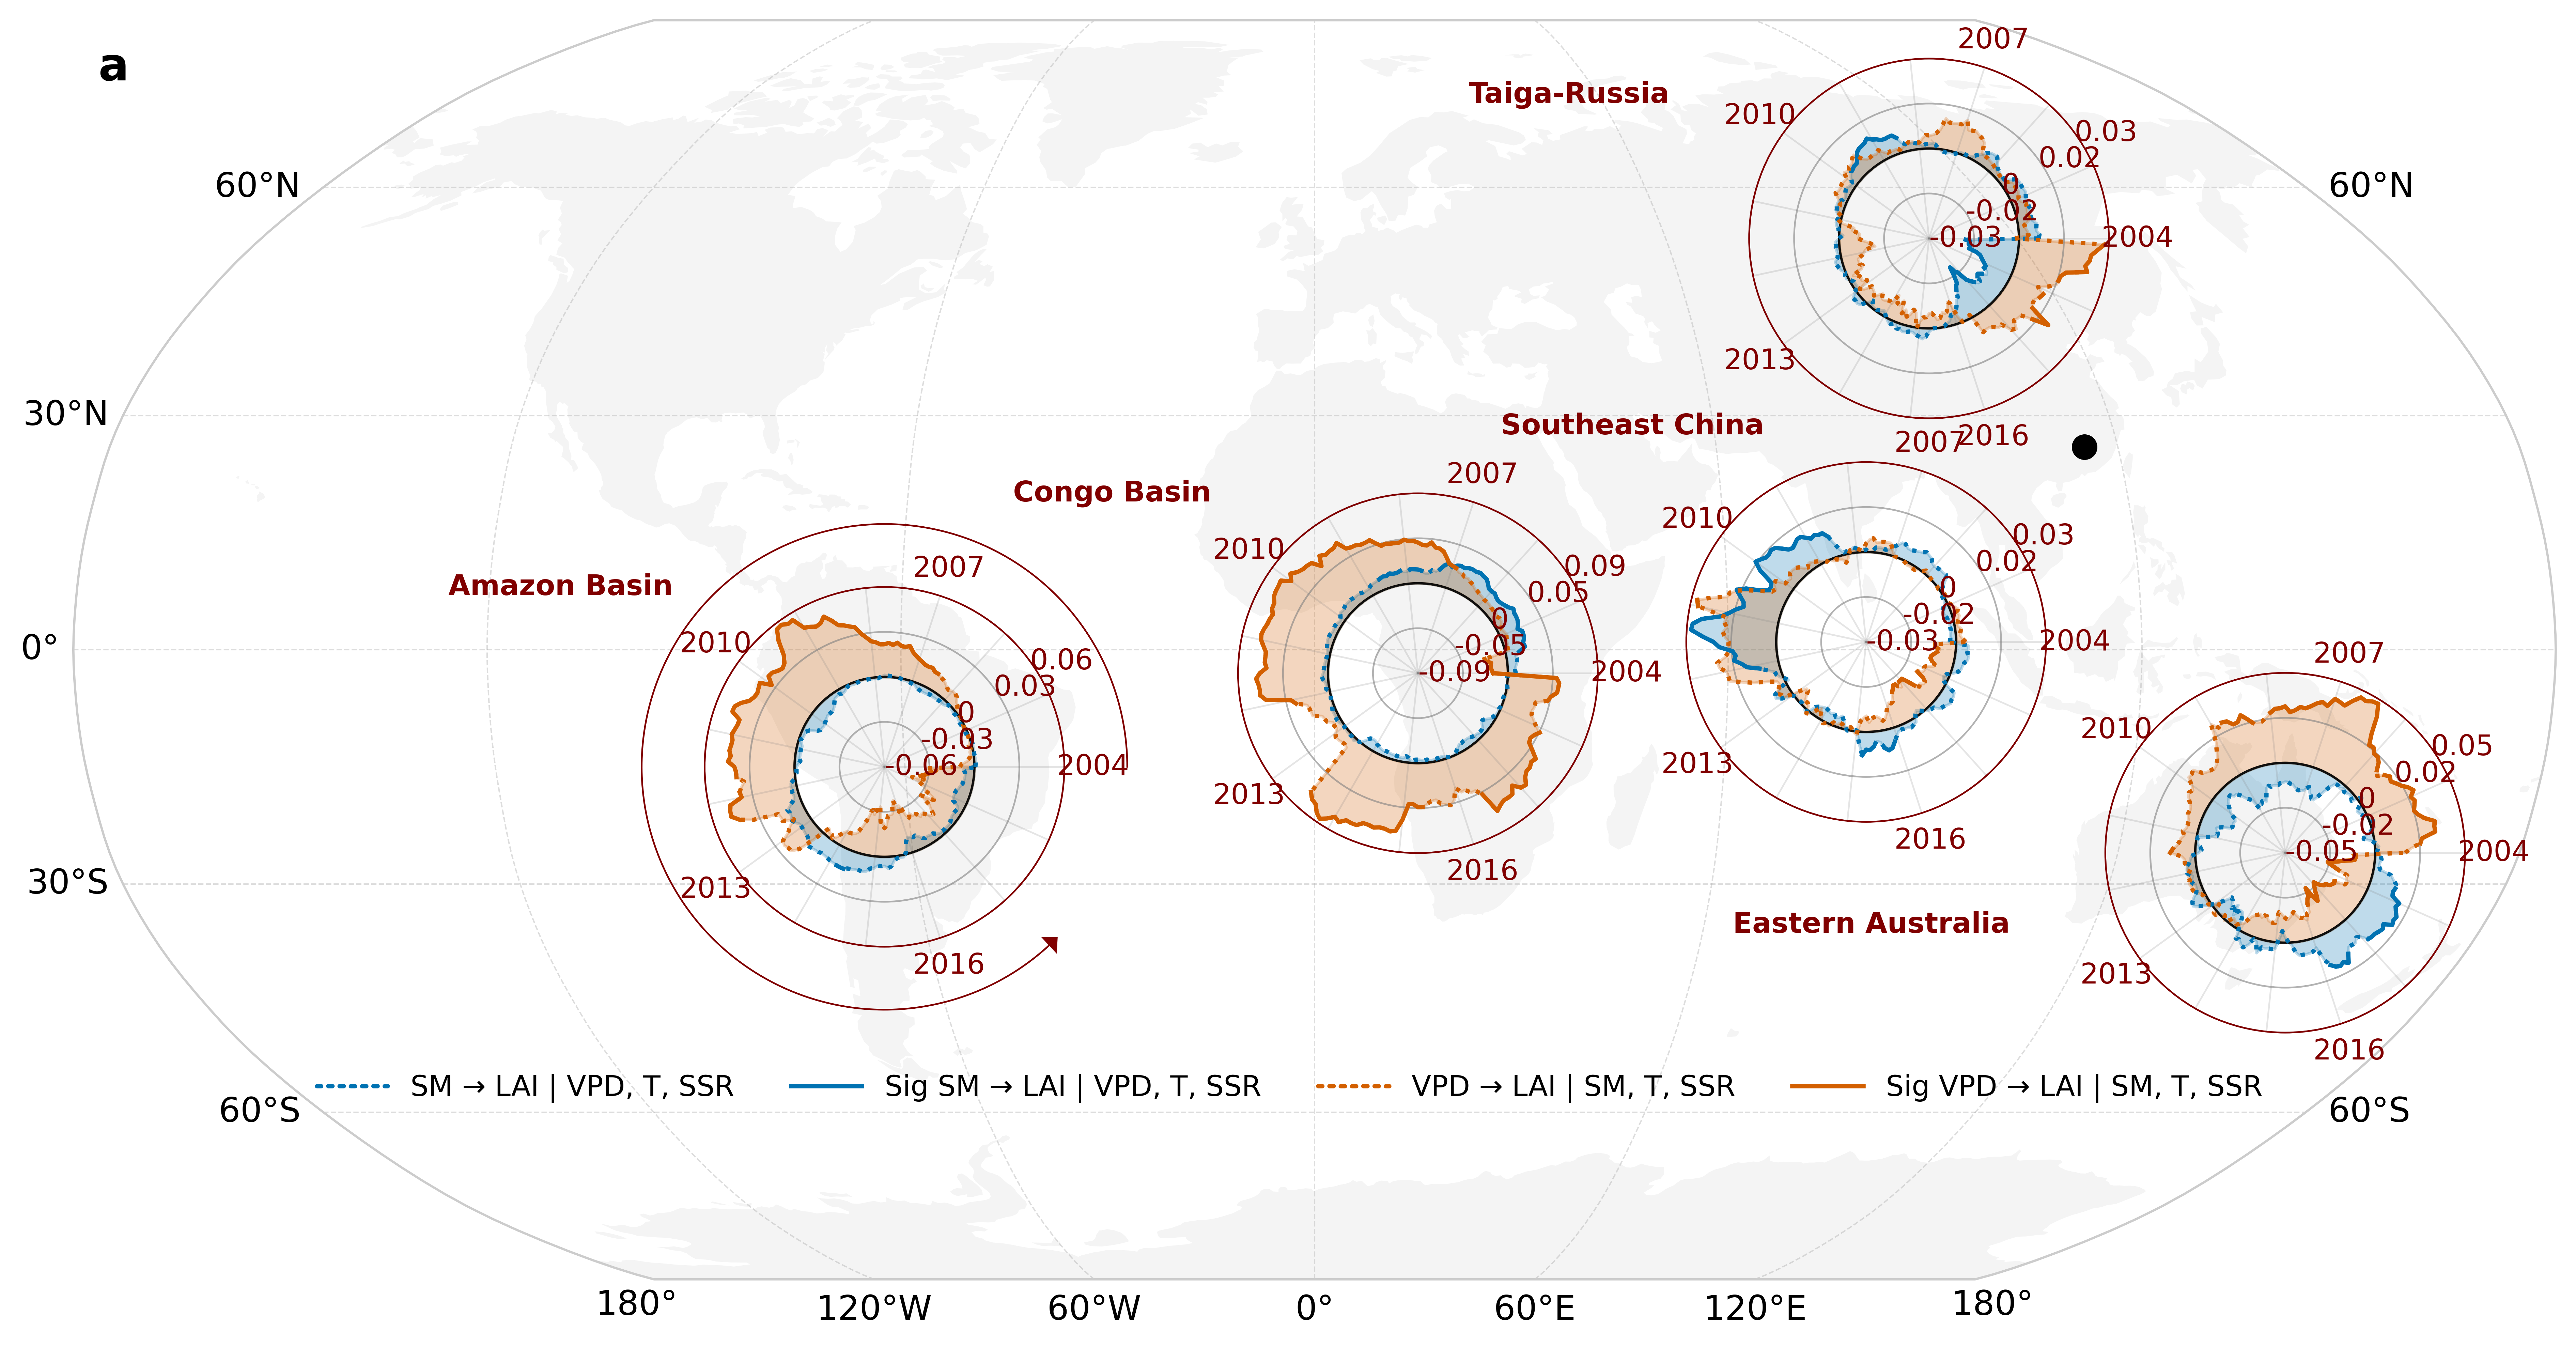

In [2]:
#LAI
from IPython.display import Image, display
import os
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==============================================================================
# 1. CORE SETUP & CONFIGURATION
# ==============================================================================
BASE_DIR = r'E:\CAZ-Again'

regions_config = {
    "Amazon Basin": {
        "folder": "Amazon", "prefix": "sm_lai_vpd_t_ssr", "v_prefix": "vpd_lai_sm_t_ssr",
        "lon": -63.0, "lat": -15.0, "size": 0.22,
        "label_x": -0.4, "label_y": 1.0       
    },
    "Congo Basin": {
        "folder": "Congo", "prefix": "sm_lai_vpd_t_ssr", "v_prefix": "vpd_lai_sm_t_ssr",
        "lon": 15.0, "lat": -3.0, "size": 0.22,
        "label_x": -0.35, "label_y": 1.0       
    },
    "Taiga-Russia": {
        "folder": "Taiga", "prefix": "sm_lai_vpd_t_ssr", "v_prefix": "vpd_lai_sm_t_ssr",
        "lon": 105.0, "lat": 53.0, "size": 0.22,
        "label_x": -0.5, "label_y": 0.9       
    },
    "Southeast China": {
        "folder": "China", "prefix": "sm_lai_vpd_t_ssr", "v_prefix": "vpd_lai_sm_t_ssr",
        "true_lon": 115.0, "true_lat": 26.0,
        "lon": 80.0, "lat": 1.0, "size": 0.22,
        "label_x": -0.15, "label_y": 1.1      
    },
    "Eastern Australia": {
        "folder": "QL", "prefix": "sm_lai_vpd_t_ssr", "v_prefix": "vpd_lai_sm_t_ssr",
        "lon": 145.0, "lat": -26.0, "size": 0.22,
        "label_x": -0.65, "label_y": 0.3       
    }
}

# ============================================================================== 
# WEIGHTED INPUT LOADER: same regional-mean threshold criterion as IF plots.
# The "masked" series masks NON-significant months with NaN; the remaining
# observations are regional IF values exceeding the weighted mean thresholds.
# ============================================================================== 
def _load_vector(model_dir, filename, variable):
    path = os.path.join(model_dir, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing weighted input: {path}")

    obj = scipy.io.loadmat(path, variable_names=[variable])
    if variable not in obj:
        raise KeyError(f"Variable {variable!r} is missing in {path}")

    arr = np.asarray(obj[variable], dtype=float).squeeze()
    if arr.ndim != 1:
        raise ValueError(f"Expected a one-dimensional time series in {path}; got {arr.shape}")
    if arr.size < 180:
        raise ValueError(f"Need 180 months in {path}; found {arr.size}")
    return arr[-180:].copy()


def load_weighted_pair(region_folder, model_name):
    """Return (full regional IF, regional IF with nonsignificant months masked)."""
    model_dir = os.path.join(BASE_DIR, region_folder, 'mean', model_name)

    IF = _load_vector(model_dir, 'T21mean.mat', 'T21mean')
    positive = _load_vector(model_dir, 'err95_positive_mean.mat', 'err95_positive_mean')
    negative = _load_vector(model_dir, 'err95_negative_mean.mat', 'err95_negative_mean')

    valid = np.isfinite(IF) & np.isfinite(positive) & np.isfinite(negative)
    exceeds_threshold = valid & ((IF > positive) | (IF < negative))

    # This matches the MATLAB regional-mean comparison from our final IF plots.
    # "Masked" = NON-significant values removed; solid line = surviving months.
    IF_masked = IF.copy()
    IF_masked[~exceeds_threshold] = np.nan

    print(f"  {region_folder}/{model_name}: "
          f"{int(exceeds_threshold.sum())} threshold-exceeding months / "
          f"{int(valid.sum())} valid months")

    return IF, IF_masked

dates = pd.date_range(start='2004-01-01', periods=180, freq='MS')
angles = np.linspace(0, 2 * np.pi, len(dates), endpoint=False)
angles_loop = np.append(angles, angles[0])

colors = ['#0072b2', '#d35f00']  
DATA_LINE_WIDTH = 1.5            
CIRCLE_WIDTH = 0.6               
ZERO_LINE_WIDTH = 0.8

# ==============================================================================
# 2. BASE GLOBAL MAP CREATION (ROBINSON PROJECTION)
# ==============================================================================
fig = plt.figure(figsize=(16, 8), dpi=400)

map_proj = ccrs.Robinson(central_longitude=0)
ax_map = fig.add_subplot(1, 1, 1, projection=map_proj)

ax_map.set_global()
ax_map.add_feature(cfeature.LAND, facecolor='#f4f4f4', edgecolor='none', zorder=0) 

# --- ADD THIS LINE TO MAKE THE OUTER MAP BOUNDARY LIGHTER ---
ax_map.spines['geo'].set_edgecolor('#cccccc') 
# ------------------------------------------------------------

gl = ax_map.gridlines(draw_labels=True, linewidth=0.5, color='#aaaaaa', alpha=0.4, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# ADD PANEL LABEL "a" IN THE TOP LEFT CORNER
ax_map.text(
    0.01, 0.98, 'a', 
    transform=ax_map.transAxes, 
    fontsize=16, 
    fontweight='bold', 
    color='black', 
    va='top', 
    ha='left', 
    zorder=20
)

fig.canvas.draw()

# ==============================================================================
# 3. DYNAMIC INSET SUBPLOT PROCESSING FOR EACH REGION
# ==============================================================================
for region_name, config in regions_config.items():
    # Load area-weighted regional IF and the weighted positive/negative thresholds.
    # Preserve the original ordering: SM complete, SM masked, VPD complete, VPD masked.
    region_folder = config["folder"]
    try:
        sm_full, sm_masked = load_weighted_pair(region_folder, config["prefix"])
        vpd_full, vpd_masked = load_weighted_pair(region_folder, config["v_prefix"])
    except (FileNotFoundError, KeyError, ValueError) as exc:
        # Do not quietly omit a region or silently substitute old unweighted data.
        raise RuntimeError(f"Cannot plot {region_name}: {exc}") from exc

    data_series = [sm_full, sm_masked, vpd_full, vpd_masked]
    finite_sets = [series[np.isfinite(series)] for series in data_series]
    if not any(group.size for group in finite_sets):
        raise ValueError(f"No finite IF values for {region_name}")

    all_data = np.concatenate([group for group in finite_sets if group.size])
    M = np.nanmax(np.abs(all_data)) * 1.05
    
    zero_radius = M
    r_min, r_max = 0, 2 * M
    tick_values = np.array([-M, -M/2, 0, M/2, M])
    tick_radii = tick_values + M

    if "true_lon" in config:
        ax_map.plot(config["true_lon"], config["true_lat"], marker='o', color='black', markersize=8, transform=ccrs.PlateCarree(), zorder=5)

    lon, lat = config["lon"], config["lat"]
    x_map, y_map = map_proj.transform_point(lon, lat, src_crs=ccrs.PlateCarree())
    x_pix, y_pix = ax_map.transData.transform((x_map, y_map))
    x_fig, y_fig = fig.transFigure.inverted().transform((x_pix, y_pix))
    
    size = config["size"]
    rect = [x_fig - size/2, y_fig - size/2, size, size]

    ax = fig.add_axes(rect, projection='polar', zorder=3)
    ax.patch.set_alpha(0.0) 

    for i, series in enumerate(data_series):
        base_index = i // 2
        is_masked = (i % 2 == 1)
        color = colors[base_index]
        linestyle = '-' if is_masked else ':'
        series_loop = np.append(series, series[0])
        r_loop = np.ma.masked_invalid(series_loop + M)

        ax.plot(angles_loop, r_loop, linewidth=DATA_LINE_WIDTH, alpha=0.99, color=color, linestyle=linestyle, zorder=6)
        if not is_masked:
            ax.fill_between(angles_loop, zero_radius, r_loop, alpha=0.25, color=color, zorder=1)

    theta_dense = np.linspace(0, 2 * np.pi, 720)
    ax.plot(theta_dense, np.full_like(theta_dense, zero_radius), color='black', linewidth=ZERO_LINE_WIDTH, alpha=0.9, zorder=2)
    ax.set_ylim(r_min, r_max)
    
    # Grid lines configuration
    ax.yaxis.grid(True, linestyle='-', linewidth=CIRCLE_WIDTH, color='grey', alpha=0.6)
    ax.xaxis.grid(True, linestyle='-', linewidth=CIRCLE_WIDTH, color='grey', alpha=0.2)

    # Scale labels inside the plot (Changed to maroon)
    ax.set_yticks(tick_radii)
    ax.set_yticklabels([])
    for val, rad in zip(tick_values, tick_radii):
        ax.text(angles[18], rad, '0' if abs(val) < 1e-10 else f'{val:.2f}', fontsize=10, color='maroon', ha='left', va='center', zorder=10)

    # Structural Grid Lines Setup for Years
    all_year_indices = [idx for idx, d in enumerate(dates) if d.month == 1]
    all_year_angles = [angles[idx] for idx in all_year_indices]
    ax.set_xticks(all_year_angles)
    ax.set_xticklabels([''] * len(all_year_angles))

    # 3-Year Labels via transAxes (Changed to maroon)
    for idx in all_year_indices:
        current_year = dates[idx].year
        if current_year in [2004, 2007, 2010, 2013, 2016]:
            theta = angles[idx]
            x_text = 0.5 + 0.58 * np.cos(theta)
            y_text = 0.5 + 0.58 * np.sin(theta)
            
            ax.text(
                x_text, y_text, str(current_year),
                transform=ax.transAxes,
                fontsize=10, fontweight='normal', color='maroon',
                ha='center', va='center', zorder=10
            )

    # Outer Boundary Configuration (Changed to maroon)
    ax.spines['polar'].set_linewidth(CIRCLE_WIDTH)
    ax.spines['polar'].set_color('maroon')

    x_pos = config.get("label_x", 0.5)
    y_pos = config.get("label_y", 1.40)
    ax.text(x_pos, y_pos, region_name, transform=ax.transAxes, fontsize=10, fontweight='bold', color='maroon', ha='center', va='center')

    # ==============================================================================
    # FIX: ROBUST MATHEMATICAL GEOMETRY ARROW (AMAZON BASIN ONLY)
    # ==============================================================================
    if region_name == "Amazon Basin":
        arrow_radius = r_max * 1.35  
        arrow_tip_theta = np.pi * 1.75
        theta_arrow_path = np.linspace(0, arrow_tip_theta, 300)
        
        # 1. Plot the clean track line segment path
        ax.plot(
            theta_arrow_path, np.full_like(theta_arrow_path, arrow_radius), 
            color='maroon', linewidth=CIRCLE_WIDTH, zorder=10, clip_on=False
        )
        
        # 2. Build a reliable manual triangle geometry block
        d_theta = 0.035          # Length of the arrowhead along the arc path
        d_r = r_max * 0.045      # Width of the arrowhead base wings
        
        # Vertices layout: [Tip Point, Upper Wing, Lower Wing]
        arrow_thetas = [arrow_tip_theta, arrow_tip_theta - d_theta, arrow_tip_theta - d_theta]
        arrow_radii = [arrow_radius, arrow_radius + d_r, arrow_radius - d_r]
        
        ax.fill(arrow_thetas, arrow_radii, color='maroon', zorder=11, clip_on=False)

# ==============================================================================
# 4. INTERNAL MAP-LEVEL HORIZONTAL LEGEND
# ==============================================================================
h1 = mlines.Line2D([], [], color='#0072b2', linestyle=':', linewidth=1.5, dash_capstyle='round')
h2 = mlines.Line2D([], [], color='#0072b2', linestyle='-', linewidth=1.5)
h3 = mlines.Line2D([], [], color='#d35f00', linestyle=':', linewidth=1.5, dash_capstyle='round')
h4 = mlines.Line2D([], [], color='#d35f00', linestyle='-', linewidth=1.5)

legend_labels = [
    "SM → LAI | VPD, T, SSR",
    "Sig SM → LAI | VPD, T, SSR",
    "VPD → LAI | SM, T, SSR",
    "Sig VPD → LAI | SM, T, SSR"
]

ax_map.legend(
    handles=[h1, h2, h3, h4],
    labels=legend_labels,
    loc='lower center',
    bbox_to_anchor=(0.49, 0.12),  
    ncol=4,
    frameon=False,
    fontsize=10,
    handlelength=2.5
)

# ==============================================================================
# 5. SAVE COMPREHENSIVE OUTPUT
# ==============================================================================
output_dir = r'E:\CAZ-Again\Figure2'
os.makedirs(output_dir, exist_ok=True)
output_svg = os.path.join(output_dir, 'LAI_maroon_area_weighted.svg')
output_png = os.path.join(output_dir, 'LAI_maroon_area_weighted.png')

plt.savefig(output_svg, format='svg', bbox_inches='tight')
plt.savefig(output_png, format='png', dpi=600, bbox_inches='tight')
plt.close()

try:
    display(Image(filename=output_png))
except Exception:
    print(f'Figure saved: {output_png}')

  Amazon/sm_gpp_vpd_t_ssr: 41 threshold-exceeding months / 180 valid months
  Amazon/vpd_gpp_sm_t_ssr: 85 threshold-exceeding months / 180 valid months
  Congo/sm_gpp_vpd_t_ssr: 5 threshold-exceeding months / 180 valid months
  Congo/vpd_gpp_sm_t_ssr: 50 threshold-exceeding months / 180 valid months
  Congo Basin: radial labels extended from [-0.12, 0.08] to [-0.126054, 0.08] to avoid clipping
  Taiga/sm_gpp_vpd_t_ssr: 47 threshold-exceeding months / 180 valid months
  Taiga/vpd_gpp_sm_t_ssr: 68 threshold-exceeding months / 180 valid months
  China/sm_gpp_vpd_t_ssr: 105 threshold-exceeding months / 180 valid months
  China/vpd_gpp_sm_t_ssr: 56 threshold-exceeding months / 180 valid months
  QL/sm_gpp_vpd_t_ssr: 27 threshold-exceeding months / 180 valid months
  QL/vpd_gpp_sm_t_ssr: 147 threshold-exceeding months / 180 valid months
  Eastern Australia: radial labels extended from [-0.2, 0.08] to [-0.2, 0.0867165] to avoid clipping


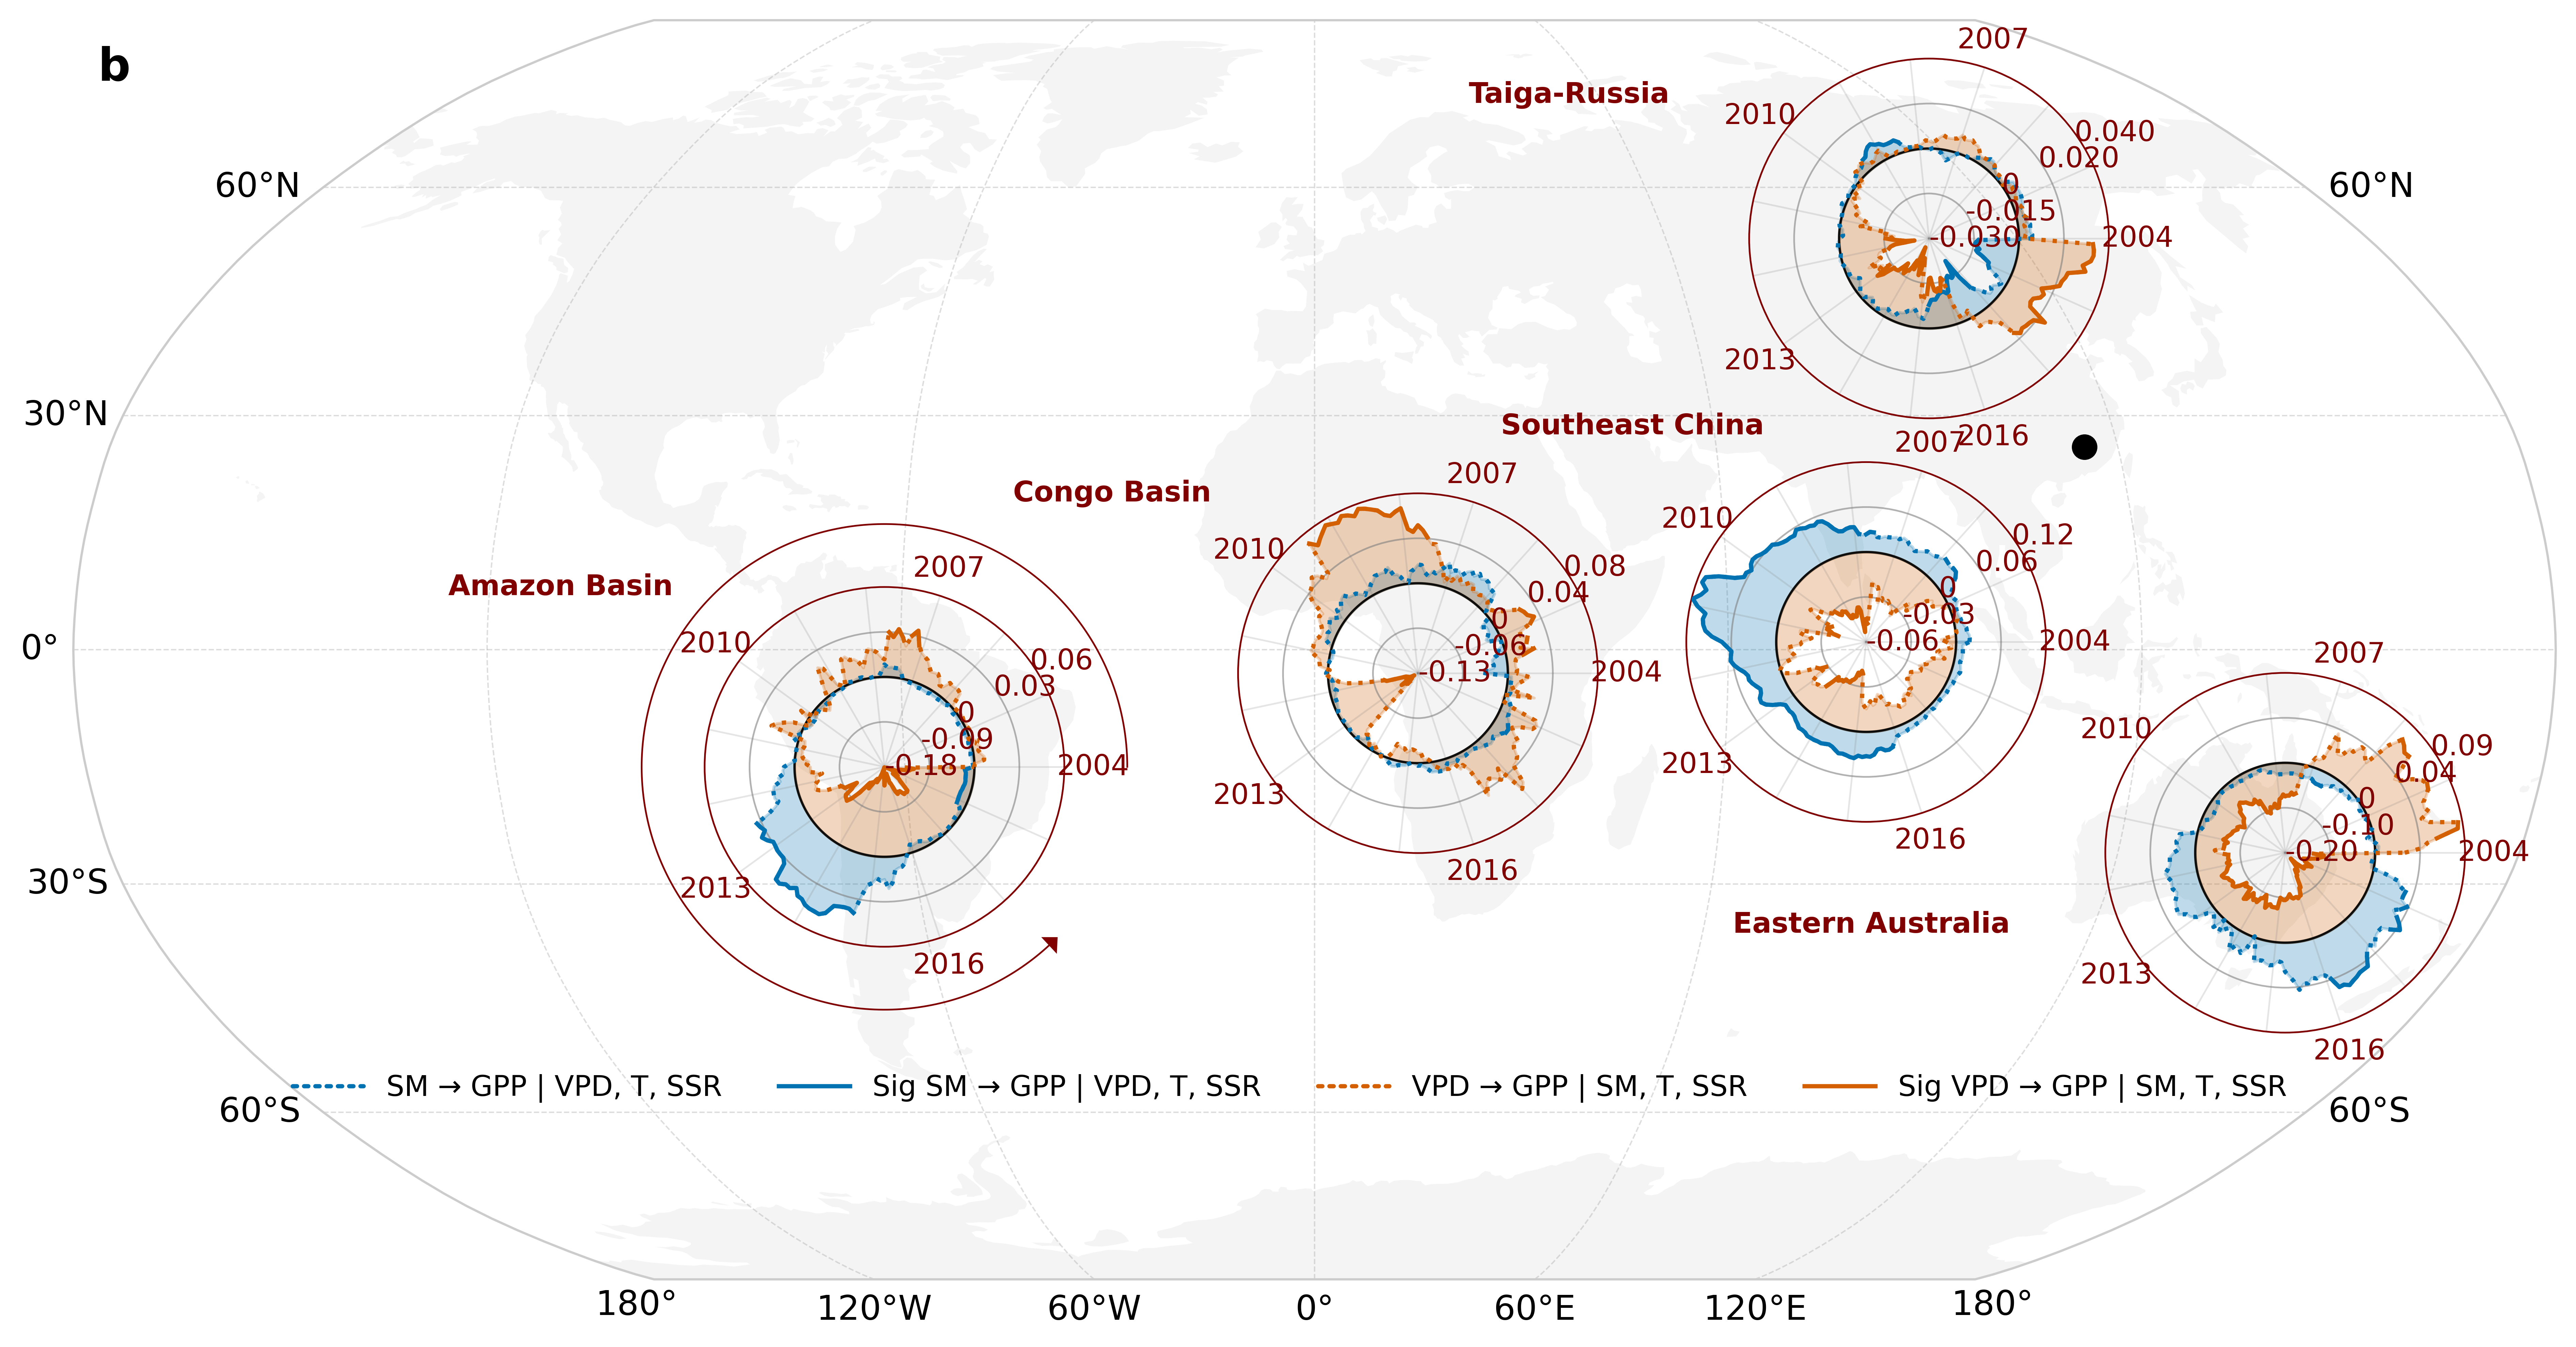

In [3]:
#GPP
from IPython.display import Image, display
import os
import scipy.io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ==============================================================================
# 1. CORE SETUP & CONFIGURATION
# ==============================================================================
BASE_DIR = r'E:\CAZ-Again'

# All region limits manually adjusted to eliminate visual compression completely
regions_config = {
    "Amazon Basin": {
        "folder": "Amazon", "prefix": "sm_gpp_vpd_t_ssr", "v_prefix": "vpd_gpp_sm_t_ssr",
        "lon": -63.0, "lat": -15.0, "size": 0.22,
        "label_x": -0.4, "label_y": 1.0,
        "v_min": -0.18, "v_max": 0.06  # Labels: -0.18, -0.09, 0, 0.03, 0.06
    },
    "Congo Basin": {
        "folder": "Congo", "prefix": "sm_gpp_vpd_t_ssr", "v_prefix": "vpd_gpp_sm_t_ssr",
        "lon": 15.0, "lat": -3.0, "size": 0.22,
        "label_x": -0.35, "label_y": 1.0,
        "v_min": -0.12, "v_max": 0.08  # Labels: -0.12, -0.06, 0, 0.04, 0.08
    },
    "Taiga-Russia": {
        "folder": "Taiga", "prefix": "sm_gpp_vpd_t_ssr", "v_prefix": "vpd_gpp_sm_t_ssr",
        "lon": 105.0, "lat": 53.0, "size": 0.22,
        "label_x": -0.5, "label_y": 0.9,
        "v_min": -0.03, "v_max": 0.04  # Labels: -0.03, -0.015, 0, 0.02, 0.04
    },
    "Southeast China": {
        "folder": "China", "prefix": "sm_gpp_vpd_t_ssr", "v_prefix": "vpd_gpp_sm_t_ssr",
        "true_lon": 115.0, "true_lat": 26.0,
        "lon": 80.0, "lat": 1.0, "size": 0.22,
        "label_x": -0.15, "label_y": 1.1,
        "v_min": -0.06, "v_max": 0.12  # Labels: -0.06, -0.03, 0, 0.06, 0.12
    },
    "Eastern Australia": {
        "folder": "QL", "prefix": "sm_gpp_vpd_t_ssr", "v_prefix": "vpd_gpp_sm_t_ssr",
        "lon": 145.0, "lat": -26.0, "size": 0.22,
        "label_x": -0.65, "label_y": 0.3,
        "v_min": -0.20, "v_max": 0.08  # Labels: -0.2, -0.1, 0, 0.04, 0.08
    }
}

# ============================================================================== 
# WEIGHTED INPUT LOADER: same regional-mean threshold criterion as IF plots.
# The "masked" series masks NON-significant months with NaN; the remaining
# observations are regional IF values exceeding the weighted mean thresholds.
# ============================================================================== 
def _load_vector(model_dir, filename, variable):
    path = os.path.join(model_dir, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing weighted input: {path}")

    obj = scipy.io.loadmat(path, variable_names=[variable])
    if variable not in obj:
        raise KeyError(f"Variable {variable!r} is missing in {path}")

    arr = np.asarray(obj[variable], dtype=float).squeeze()
    if arr.ndim != 1:
        raise ValueError(f"Expected a one-dimensional time series in {path}; got {arr.shape}")
    if arr.size < 180:
        raise ValueError(f"Need 180 months in {path}; found {arr.size}")
    return arr[-180:].copy()


def load_weighted_pair(region_folder, model_name):
    """Return (full regional IF, regional IF with nonsignificant months masked)."""
    model_dir = os.path.join(BASE_DIR, region_folder, 'mean', model_name)

    IF = _load_vector(model_dir, 'T21mean.mat', 'T21mean')
    positive = _load_vector(model_dir, 'err95_positive_mean.mat', 'err95_positive_mean')
    negative = _load_vector(model_dir, 'err95_negative_mean.mat', 'err95_negative_mean')

    valid = np.isfinite(IF) & np.isfinite(positive) & np.isfinite(negative)
    exceeds_threshold = valid & ((IF > positive) | (IF < negative))

    # This matches the MATLAB regional-mean comparison from our final IF plots.
    # "Masked" = NON-significant values removed; solid line = surviving months.
    IF_masked = IF.copy()
    IF_masked[~exceeds_threshold] = np.nan

    print(f"  {region_folder}/{model_name}: "
          f"{int(exceeds_threshold.sum())} threshold-exceeding months / "
          f"{int(valid.sum())} valid months")

    return IF, IF_masked

dates = pd.date_range(start='2004-01-01', periods=180, freq='MS')
angles = np.linspace(0, 2 * np.pi, len(dates), endpoint=False)
angles_loop = np.append(angles, angles[0])

colors = ['#0072b2', '#d35f00']  
DATA_LINE_WIDTH = 1.5            
CIRCLE_WIDTH = 0.6               
ZERO_LINE_WIDTH = 0.8

# ==============================================================================
# 2. BASE GLOBAL MAP CREATION (ROBINSON PROJECTION)
# ==============================================================================
fig = plt.figure(figsize=(16, 8), dpi=400)

map_proj = ccrs.Robinson(central_longitude=0)
ax_map = fig.add_subplot(1, 1, 1, projection=map_proj)

ax_map.set_global()
ax_map.add_feature(cfeature.LAND, facecolor='#f4f4f4', edgecolor='none', zorder=0) 

# --- ADD THIS LINE TO MAKE THE OUTER MAP BOUNDARY LIGHTER ---
ax_map.spines['geo'].set_edgecolor('#cccccc') 
# ------------------------------------------------------------

gl = ax_map.gridlines(draw_labels=True, linewidth=0.5, color='#aaaaaa', alpha=0.4, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# ADD PANEL LABEL "b" IN THE TOP LEFT CORNER
ax_map.text(
    0.01, 0.98, 'b', 
    transform=ax_map.transAxes, 
    fontsize=16, 
    fontweight='bold', 
    color='black', 
    va='top', 
    ha='left', 
    zorder=20
)

fig.canvas.draw()

# ==============================================================================
# 3. DYNAMIC INSET SUBPLOT PROCESSING FOR EACH REGION
# ==============================================================================
for region_name, config in regions_config.items():
    # Load area-weighted regional IF and the weighted positive/negative thresholds.
    # Preserve the original ordering: SM complete, SM masked, VPD complete, VPD masked.
    region_folder = config["folder"]
    try:
        sm_full, sm_masked = load_weighted_pair(region_folder, config["prefix"])
        vpd_full, vpd_masked = load_weighted_pair(region_folder, config["v_prefix"])
    except (FileNotFoundError, KeyError, ValueError) as exc:
        # Do not quietly omit a region or silently substitute old unweighted data.
        raise RuntimeError(f"Cannot plot {region_name}: {exc}") from exc

    data_series = [sm_full, sm_masked, vpd_full, vpd_masked]
    finite_sets = [series[np.isfinite(series)] for series in data_series]
    if not any(group.size for group in finite_sets):
        raise ValueError(f"No finite IF values for {region_name}")

    # Setup core geometric matrix constraints (Preserves original spatial configuration)
    all_data = np.concatenate([group for group in finite_sets if group.size])
    M_geom = np.nanmax(np.abs(all_data)) * 1.05
    
    zero_radius = M_geom
    r_min, r_max = 0, 2 * M_geom
    tick_radii = np.array([0, M_geom/2, M_geom, M_geom + M_geom/2, 2 * M_geom])

    # Assign text tracking values based on custom constraints
    v_min = config["v_min"]
    v_max = config["v_max"]

    # Retain the old GPP asymmetric scale when it covers the new weighted data.
    # Expand it only if needed, so no weighted observations are cut off.
    observed_min = float(np.nanmin(all_data))
    observed_max = float(np.nanmax(all_data))
    if observed_min < v_min or observed_max > v_max:
        old_min, old_max = v_min, v_max
        v_min = min(v_min, observed_min * 1.05 if observed_min < 0 else observed_min)
        v_max = max(v_max, observed_max * 1.05 if observed_max > 0 else observed_max)
        print(f"  {region_name}: radial labels extended from "
              f"[{old_min:g}, {old_max:g}] to [{v_min:g}, {v_max:g}] to avoid clipping")
    
    # Construct completely custom asymmetric text labels
    tick_labels = [v_min, v_min/2, 0, v_max/2, v_max]

    if "true_lon" in config:
        ax_map.plot(config["true_lon"], config["true_lat"], marker='o', color='black', markersize=8, transform=ccrs.PlateCarree(), zorder=5)

    lon, lat = config["lon"], config["lat"]
    x_map, y_map = map_proj.transform_point(lon, lat, src_crs=ccrs.PlateCarree())
    x_pix, y_pix = ax_map.transData.transform((x_map, y_map))
    x_fig, y_fig = fig.transFigure.inverted().transform((x_pix, y_pix))
    
    size = config["size"]
    rect = [x_fig - size/2, y_fig - size/2, size, size]

    ax = fig.add_axes(rect, projection='polar', zorder=3)
    ax.patch.set_alpha(0.0) 

    for i, series in enumerate(data_series):
        base_index = i // 2
        is_masked = (i % 2 == 1)
        color = colors[base_index]
        linestyle = '-' if is_masked else ':'
        series_loop = np.append(series, series[0])
        
        # Maps raw uneven negative/positive values cleanly into equal-interval spatial geometry
        r_loop = np.zeros_like(series_loop)
        for idx, val in enumerate(series_loop):
            if np.isnan(val) or np.isinf(val):
                r_loop[idx] = np.nan
            elif val < 0:
                # Map negative track linearly between r=0 (v_min) and r=M_geom (0)
                r_loop[idx] = M_geom * (1.0 - (val / v_min))
            else:
                # Map positive track linearly between r=M_geom (0) and r=2*M_geom (v_max)
                r_loop[idx] = M_geom + M_geom * (val / v_max)
                
        r_loop = np.ma.masked_invalid(r_loop)

        ax.plot(angles_loop, r_loop, linewidth=DATA_LINE_WIDTH, alpha=0.99, color=color, linestyle=linestyle, zorder=6)
        if not is_masked:
            ax.fill_between(angles_loop, zero_radius, r_loop, alpha=0.25, color=color, zorder=1)

    theta_dense = np.linspace(0, 2 * np.pi, 720)
    ax.plot(theta_dense, np.full_like(theta_dense, zero_radius), color='black', linewidth=ZERO_LINE_WIDTH, alpha=0.9, zorder=2)
    ax.set_ylim(r_min, r_max)
    
    # Grid lines configuration
    ax.yaxis.grid(True, linestyle='-', linewidth=CIRCLE_WIDTH, color='grey', alpha=0.6)
    ax.xaxis.grid(True, linestyle='-', linewidth=CIRCLE_WIDTH, color='grey', alpha=0.2)

    # Scale labels inside the plot (Displays custom asymmetrical text ticks dynamically)
    ax.set_yticks(tick_radii)
    ax.set_yticklabels([])
    for display_val, rad in zip(tick_labels, tick_radii):
        # Format strings conditionally to display precise 3-digit precision for tiny Taiga decimals if needed
        fmt = f'{display_val:.3f}' if abs(v_min) < 0.05 else f'{display_val:.2f}'
        ax.text(angles[18], rad, '0' if abs(display_val) < 1e-10 else fmt, fontsize=10, color='maroon', ha='left', va='center', zorder=10)

    # Structural Grid Lines Setup for Years
    all_year_indices = [idx for idx, d in enumerate(dates) if d.month == 1]
    all_year_angles = [angles[idx] for idx in all_year_indices]
    ax.set_xticks(all_year_angles)
    ax.set_xticklabels([''] * len(all_year_angles))

    # 3-Year Labels via transAxes
    for idx in all_year_indices:
        current_year = dates[idx].year
        if current_year in [2004, 2007, 2010, 2013, 2016]:
            theta = angles[idx]
            x_text = 0.5 + 0.58 * np.cos(theta)
            y_text = 0.5 + 0.58 * np.sin(theta)
            
            ax.text(
                x_text, y_text, str(current_year),
                transform=ax.transAxes,
                fontsize=10, fontweight='normal', color='maroon',
                ha='center', va='center', zorder=10
            )

    # Outer Boundary Configuration
    ax.spines['polar'].set_linewidth(CIRCLE_WIDTH)
    ax.spines['polar'].set_color('maroon')

    x_pos = config.get("label_x", 0.5)
    y_pos = config.get("label_y", 1.40)
    ax.text(x_pos, y_pos, region_name, transform=ax.transAxes, fontsize=10, fontweight='bold', color='maroon', ha='center', va='center')

    # ==============================================================================
    # FIX: ROBUST MATHEMATICAL GEOMETRY ARROW (AMAZON BASIN ONLY)
    # ==============================================================================
    if region_name == "Amazon Basin":
        arrow_radius = r_max * 1.35  
        arrow_tip_theta = np.pi * 1.75
        theta_arrow_path = np.linspace(0, arrow_tip_theta, 300)
        
        # 1. Plot the clean track line segment path
        ax.plot(
            theta_arrow_path, np.full_like(theta_arrow_path, arrow_radius), 
            color='maroon', linewidth=CIRCLE_WIDTH, zorder=10, clip_on=False
        )
        
        # 2. Build a reliable manual triangle geometry block
        d_theta = 0.035          # Length of the arrowhead along the arc path
        d_r = r_max * 0.045      # Width of the arrowhead base wings
        
        # Vertices layout: [Tip Point, Upper Wing, Lower Wing]
        arrow_thetas = [arrow_tip_theta, arrow_tip_theta - d_theta, arrow_tip_theta - d_theta]
        arrow_radii = [arrow_radius, arrow_radius + d_r, arrow_radius - d_r]
        
        ax.fill(arrow_thetas, arrow_radii, color='maroon', zorder=11, clip_on=False)

# ==============================================================================
# 4. INTERNAL MAP-LEVEL HORIZONTAL LEGEND
# ==============================================================================
h1 = mlines.Line2D([], [], color='#0072b2', linestyle=':', linewidth=1.5, dash_capstyle='round')
h2 = mlines.Line2D([], [], color='#0072b2', linestyle='-', linewidth=1.5)
h3 = mlines.Line2D([], [], color='#d35f00', linestyle=':', linewidth=1.5, dash_capstyle='round')
h4 = mlines.Line2D([], [], color='#d35f00', linestyle='-', linewidth=1.5)

legend_labels = [
    "SM → GPP | VPD, T, SSR",
    "Sig SM → GPP | VPD, T, SSR",
    "VPD → GPP | SM, T, SSR",
    "Sig VPD → GPP | SM, T, SSR"
]

ax_map.legend(
    handles=[h1, h2, h3, h4],
    labels=legend_labels,
    loc='lower center',
    bbox_to_anchor=(0.49, 0.12),  
    ncol=4,
    frameon=False,
    fontsize=10,
    handlelength=2.5
)

# ==============================================================================
# 5. SAVE COMPREHENSIVE OUTPUT
# ==============================================================================
output_dir = r'E:\CAZ-Again\Figure2'
os.makedirs(output_dir, exist_ok=True)
output_svg = os.path.join(output_dir, 'GPP_maroon_area_weighted.svg')
output_png = os.path.join(output_dir, 'GPP_maroon_area_weighted.png')

plt.savefig(output_svg, format='svg', bbox_inches='tight')
plt.savefig(output_png, format='png', dpi=600, bbox_inches='tight')
plt.close()

try:
    display(Image(filename=output_png))
except Exception:
    print(f'Figure saved: {output_png}')

In [5]:
#Stacked them

import os
from PIL import Image

def stack_publication_figures(img1_path, img2_path, output_path):
    """
    Stacks two independently saved high-resolution figures perfectly on top 
    of each other without any modification to the original script layouts.
    """
    if not (os.path.exists(img1_path) and os.path.exists(img2_path)):
        print("Error: One or both source images were not found. Please run script 1 and script 2 first.")
        return
        
    # Open the two generated high-DPI images
    im1 = Image.open(img1_path)
    im2 = Image.open(img2_path)
    
    # Ensure they match in width (rescale im2 to match im1 if there is a minor DPI difference)
    if im1.width != im2.width:
        scale_factor = im1.width / im2.width
        new_height = int(im2.height * scale_factor)
        im2 = im2.resize((im1.width, new_height), Image.Resampling.LANCZOS)
    
    # Create a blank composite canvas with combined height
    combined_height = im1.height + im2.height
    stacked_image = Image.new("RGBA", (im1.width, combined_height), color="white")
    
    # Paste both figures perfectly cleanly
    stacked_image.paste(im1, (0, 0))
    stacked_image.paste(im2, (0, im1.height))
    
    # Save output for your publication directory
    stacked_image.save(output_path, dpi=im1.info.get('dpi', (600, 600)))
    print(f"Successfully created stacked publication figure at:\n{output_path}")

# ==============================================================================
# EXECUTE STACKING FUNCTION
# ==============================================================================
# Paths exactly matching your existing script outputs:
script1_output = r'E:\CAZ-Again\Figure2\LAI_maroon_area_weighted.png'
script2_output = r'E:\CAZ-Again\Figure2\GPP_maroon_area_weighted.png'
final_stacked_output = r'E:\CAZ-Again\Figure2\LAI_GPP_Stacked.png'

stack_publication_figures(script1_output, script2_output, final_stacked_output)

Successfully created stacked publication figure at:
E:\CAZ-Again\Figure2\LAI_GPP_Stacked.png
